In [ ]:
Credit Scoring Model

### CodeAlpha Machine Learning Internship

**Objective:**
To predict an individual's creditworthiness using past financial data and machine learning classification algorithms.

**Models Used:**
- Logistic Regression
- Random Forest Classifier

**Evaluation Metrics:**
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
from sklearn.datasets import fetch_openml

credit = fetch_openml(
    name="credit-g",
    version=1,
    as_frame=True
)

df = credit.frame

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 21)


In [6]:
df.head()


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  housing                 1

In [8]:
df['class'].value_counts()

,count
class,
good,700
bad,300


In [9]:
class

SyntaxError: invalid syntax (3133579176.py, line 1)

In [10]:
X = df.drop('class', axis=1)
y = df['class']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1000, 20)
Target shape: (1000,)


In [11]:
categorical_cols = X.select_dtypes(include=['category', 'object']).columns
numerical_cols = X.select_dtypes(include=['number']).columns

print("Categorical columns:")
print(list(categorical_cols))

print("\nNumerical columns:")
print(list(numerical_cols))

Categorical columns:
['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']

Numerical columns:
['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']


In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 20)
Testing data: (200, 20)


In [15]:
logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [16]:
y_pred_lr = logistic_model.predict(X_test)

print("Predictions:")
print(y_pred_lr[:10])

Predictions:
['good' 'bad' 'bad' 'good' 'bad' 'good' 'good' 'good' 'bad' 'good']


In [17]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr, pos_label='good')
recall_lr = recall_score(y_test, y_pred_lr, pos_label='good')
f1_lr = f1_score(y_test, y_pred_lr, pos_label='good')

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

roc_auc_lr = roc_auc_score(
    (y_test == 'good').astype(int),
    y_prob_lr
)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", accuracy_lr)
print("Precision:", precision_lr)
print("Recall   :", recall_lr)
print("F1-Score :", f1_lr)
print("ROC-AUC  :", roc_auc_lr)

Logistic Regression Results
---------------------------
Accuracy : 0.705
Precision: 0.7755102040816326
Recall   : 0.8142857142857143
F1-Score : 0.794425087108014
ROC-AUC  : 0.7594047619047619


In [20]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [21]:
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Predictions:")
print(y_pred_rf[:10])

Random Forest Predictions:
['good' 'bad' 'good' 'good' 'good' 'good' 'good' 'good' 'bad' 'good']


In [22]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, pos_label='good')
recall_rf = recall_score(y_test, y_pred_rf, pos_label='good')
f1_rf = f1_score(y_test, y_pred_rf, pos_label='good')

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(
    (y_test == 'good').astype(int),
    y_prob_rf
)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1-Score :", f1_rf)
print("ROC-AUC  :", roc_auc_rf)

Random Forest Results
---------------------
Accuracy : 0.76
Precision: 0.7987012987012987
Recall   : 0.8785714285714286
F1-Score : 0.8367346938775511
ROC-AUC  : 0.7799404761904762


In [23]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy_lr, accuracy_rf],
    'Precision': [precision_lr, precision_rf],
    'Recall': [recall_lr, recall_rf],
    'F1-Score': [f1_lr, f1_rf],
    'ROC-AUC': [roc_auc_lr, roc_auc_rf]
})

results

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.705,0.775510,0.814286,0.794425,0.759405
1,Random Forest,0.760,0.798701,0.878571,0.836735,0.779940


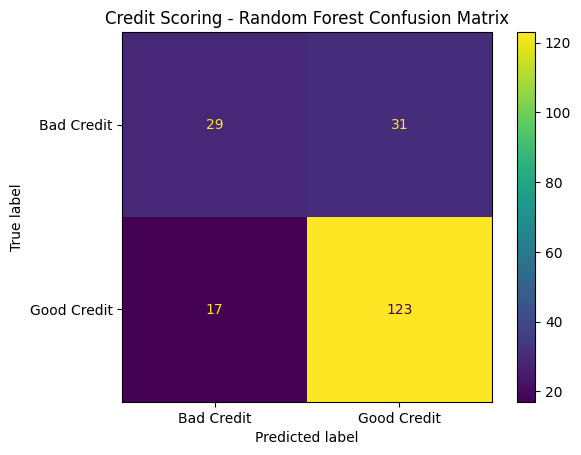

In [24]:
cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Bad Credit', 'Good Credit']
)

disp.plot()
plt.title("Credit Scoring - Random Forest Confusion Matrix")
plt.show()

In [25]:
# Sample prediction using the trained Random Forest model

sample_data = X_test.iloc[[0]]

prediction = rf_model.predict(sample_data)

print("Predicted Credit Status:", prediction[0])

Predicted Credit Status: good


In [26]:
import joblib

joblib.dump(rf_model, 'credit_scoring_random_forest.pkl')

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [ ]:
Conclusion

The Credit Scoring Model was developed using Logistic Regression and Random Forest classification algorithms.

Both models were evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

Among the two models, Random Forest achieved better overall performance, with an accuracy of 76.0% and an F1-Score of 83.67%.

The trained Random Forest model successfully predicted the credit status of a sample applicant as Good Credit.